In [1]:
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report, roc_curve

from data_setup import TESSDataset, create_dataloaders
from torch.utils.data import DataLoader

In [2]:
RANDOM_SEED = 42

def set_seed(seed: int = 42):
    """Locks down all random number generators for strict reproducibility."""
    # 1. Set Python random seed
    random.seed(seed)
    
    # 2. Set Python environment seed
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # 3. Set NumPy seed
    np.random.seed(seed)
    
    # 4. Set PyTorch CPU seed
    torch.manual_seed(seed)
    
    # 5. Set PyTorch Apple Silicon (MPS) seed
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
        
    # 6. Set PyTorch CUDA seeds (Standard practice to include for portability)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

In [3]:
device = "mps" if torch.backends.mps.is_available() else "cpu"

if device == 'mps':
    torch.mps.manual_seed(RANDOM_SEED)

device

'mps'

In [4]:
csv_path = "data/processed_labels_v2.csv"
data_dir = "data/lightcurves_v2"
BATCH_SIZE = 32

In [5]:
def accuracy_fn(y_true, y_pred):
    y_pred_rounded = torch.round(y_pred)
    
    y_true_int = y_true.cpu().int()
    y_pred_int = y_pred_rounded.cpu().int()
    
    correct = torch.eq(y_true_int, y_pred_int).sum().item() 
    
    acc = (correct / len(y_pred)) * 100 
    return acc

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class TESSModelV5Aux(nn.Module):
    def __init__(self, n_aux_features = 1):
        super().__init__()
        
        self.aux_branch = nn.Sequential(
            nn.Linear(n_aux_features, 16),
            nn.ReLU(),
        )

        self.global_view = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16,
                kernel_size = 61,
                stride = 4,
                #padding = 30
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 4),
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32,
                kernel_size = 31,
                stride = 2,
                padding = 15
            ),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 4)
        )

        self.focused_view = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16,
                kernel_size = 5,
                stride = 2,
                #padding = 10
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 2),
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32,
                kernel_size = 5,
                stride = 1,
                #padding = 3
            ), 
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features = 128 + 16, out_features = 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.1),
            nn.Dropout(p = 0.5), 
            nn.Linear(in_features = 128, out_features = 1)
        )

    def pool_branch(self, feat):
        avg = F.adaptive_avg_pool1d(feat, 1).squeeze(-1)
        mn = -F.adaptive_max_pool1d(-feat, 1).squeeze(-1)
        return torch.cat([avg, mn], dim = 1)
        
    def forward(self, x, aux):
        x_focused = x[:, :, 9000:11000]

        global_output = self.global_view(x)
        focused_output = self.focused_view(x_focused)

        global_summary  = self.pool_branch(global_output)
        focused_summary = self.pool_branch(focused_output)
        
        merge_views = torch.cat([global_summary, focused_summary], dim = 1)

        aux_out = self.aux_branch(aux)

        return self.classifier(torch.cat([merge_views, aux_out], dim = 1))

In [7]:
import torch, torch.optim as optim, copy
import numpy as np, pandas as pd
from sklearn.metrics import roc_curve, classification_report, confusion_matrix

aux_cols = ["log_period", "log_depth", "log_duration_fraction"]
results, per_seed_reports, shortcut_gaps = [], [], []
summed_cm = np.zeros((2, 2), dtype=int)

for seed in [1, 2, 3, 4, 5]:
    set_seed(seed)
    train_dataloader, test_dataloader = create_dataloaders(
        csv_path = csv_path,
        data_dir = data_dir,
        batch_size = BATCH_SIZE,
        aux_cols = aux_cols,
        seed = seed
    )
    model_5aux = TESSModelV5Aux(n_aux_features=len(aux_cols)).to(device)
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model_5aux.parameters(), lr=0.001, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    best_test_loss = float('inf'); best_model_weights = None; best_epoch = 0
    for epoch in range(100):
        model_5aux.train()
        for X, y, aux in train_dataloader:
            X, y, aux = X.to(device), y.to(device), aux.to(device)
            mean = X.mean(dim=2, keepdim=True); std = X.std(dim=2, keepdim=True)
            X = (X - mean) / (std + 1e-8)
            y = y.float().unsqueeze(dim=1)
            loss = loss_fn(model_5aux(X, aux), y)
            optimizer.zero_grad(); loss.backward(); optimizer.step()

        model_5aux.eval()
        test_loss = 0
        with torch.inference_mode():
            for X_test, y_test, aux_test in test_dataloader:
                X_test, y_test, aux_test = X_test.to(device), y_test.to(device), aux_test.to(device)
                mean = X_test.mean(dim=2, keepdim=True); std = X_test.std(dim=2, keepdim=True)
                X_test_n = (X_test - mean) / (std + 1e-8)
                y_test = y_test.float().unsqueeze(dim=1)
                test_loss += loss_fn(model_5aux(X_test_n, aux_test), y_test).item()
        test_loss /= len(test_dataloader)
        scheduler.step(test_loss)
        if test_loss < best_test_loss:
            best_test_loss = test_loss; best_epoch = epoch
            best_model_weights = copy.deepcopy(model_5aux.state_dict())

    model_5aux.load_state_dict(best_model_weights)
    torch.save(best_model_weights, f"model_durfrac_seed_{seed}.pt")
    print(f"Seed {seed} | best epoch {best_epoch}, test loss {best_test_loss:.4f}")

    model_5aux.eval()
    all_true, all_probs, all_raw_flux = [], [], []
    with torch.inference_mode():
        for X_test, y_test, aux_test in test_dataloader:
            X_test, aux_test = X_test.to(device), aux_test.to(device)
            all_raw_flux.append(X_test.cpu())
            mean = X_test.mean(dim=2, keepdim=True); std = X_test.std(dim=2, keepdim=True)
            X_test_n = (X_test - mean) / (std + 1e-8)
            probs = torch.sigmoid(model_5aux(X_test_n, aux_test)).squeeze().cpu().numpy()
            all_probs.extend(np.atleast_1d(probs))
            all_true.extend(np.atleast_1d(y_test.squeeze().cpu().numpy()))

    all_true, all_probs = np.array(all_true), np.array(all_probs)
    X_test_raw = torch.cat(all_raw_flux)

    fpr, tpr, thresholds = roc_curve(all_true, all_probs)
    opt_threshold = thresholds[np.argmax(tpr - fpr)]
    all_preds = (all_probs >= opt_threshold).astype(int)

    report = classification_report(all_true, all_preds, target_names=['No Planet (0)', 'Planet (1)'], output_dict=True)
    per_seed_reports.append(report)
    summed_cm += confusion_matrix(all_true, all_preds)
    results.append({"seed": seed, "test_acc": report["accuracy"], "test_loss": best_test_loss})

    depths = 1.0 - X_test_raw.amin(dim=2).squeeze().numpy()
    shallow_p = (all_true == 1) & (depths < 0.01); deep_p = (all_true == 1) & (depths >= 0.03)
    shallow_np = (all_true == 0) & (depths < 0.01); deep_np = (all_true == 0) & (depths >= 0.03)
    planet_gap = all_probs[deep_p].mean() - all_probs[shallow_p].mean()
    np_gap = all_probs[deep_np].mean() - all_probs[shallow_np].mean()
    shortcut_gaps.append({"seed": seed, "planet_gap": planet_gap, "no_planet_gap": np_gap})
    print(f"  Planet gap: {planet_gap:.4f}, No-Planet gap: {np_gap:.4f}")

results_df = pd.DataFrame(results)
print(results_df)
print(f"Mean accuracy: {results_df['test_acc'].mean():.3f} ± {results_df['test_acc'].std():.3f}")

gaps_df = pd.DataFrame(shortcut_gaps)
print(gaps_df)
print(f"Mean Planet gap: {gaps_df['planet_gap'].mean():.4f} ± {gaps_df['planet_gap'].std():.4f}")
print(f"Mean No-Planet gap: {gaps_df['no_planet_gap'].mean():.4f} ± {gaps_df['no_planet_gap'].std():.4f}")

/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Seed 1 | best epoch 96, test loss 0.5804
  Planet gap: 0.1024, No-Planet gap: 0.1173


/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Seed 2 | best epoch 49, test loss 0.5889
  Planet gap: 0.0947, No-Planet gap: 0.1285


/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Seed 3 | best epoch 44, test loss 0.5614
  Planet gap: 0.1376, No-Planet gap: 0.1277


/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.
Seed 4 | best epoch 88, test loss 0.5679
  Planet gap: 0.1175, No-Planet gap: 0.1189
Dataset initialized with 1784 strictly synced samples.
Dataset initialized with 447 strictly synced samples.


/Users/Vallabh/Desktop/ML/TESS_ML/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


Seed 5 | best epoch 51, test loss 0.5540
  Planet gap: 0.1252, No-Planet gap: 0.1197
   seed  test_acc  test_loss
0     1  0.706935   0.580376
1     2  0.686801   0.588881
2     3  0.704698   0.561413
3     4  0.697987   0.567934
4     5  0.700224   0.554006
Mean accuracy: 0.699 ± 0.008
   seed  planet_gap  no_planet_gap
0     1    0.102432       0.117327
1     2    0.094674       0.128494
2     3    0.137577       0.127747
3     4    0.117472       0.118877
4     5    0.125195       0.119721
Mean Planet gap: 0.1155 ± 0.0172
Mean No-Planet gap: 0.1224 ± 0.0053


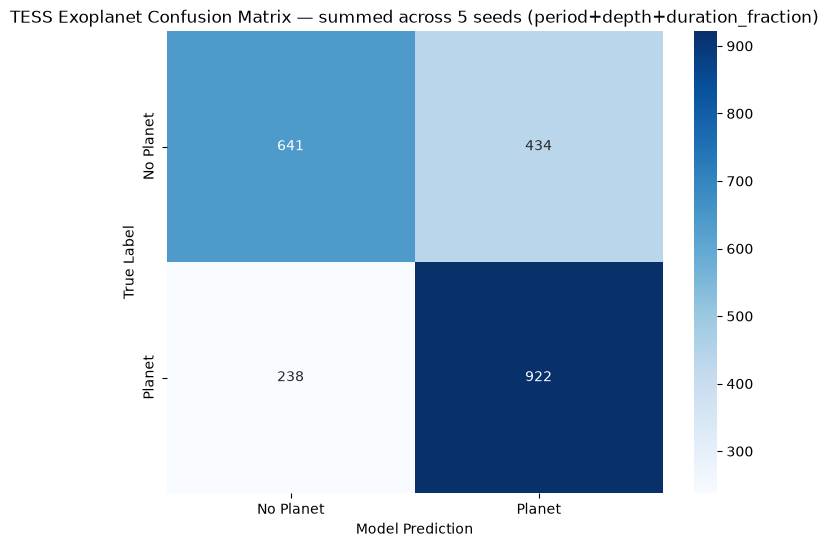

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(summed_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Planet', 'Planet'], yticklabels=['No Planet', 'Planet'])
plt.title("TESS Exoplanet Confusion Matrix — summed across 5 seeds (period+depth+duration_fraction)")
plt.ylabel("True Label")
plt.xlabel("Model Prediction")
plt.show()

Optimal threshold: 0.445
               precision    recall  f1-score   support

No Planet (0)       0.79      0.52      0.63       215
   Planet (1)       0.66      0.88      0.75       232

     accuracy                           0.70       447
    macro avg       0.73      0.70      0.69       447
 weighted avg       0.72      0.70      0.69       447



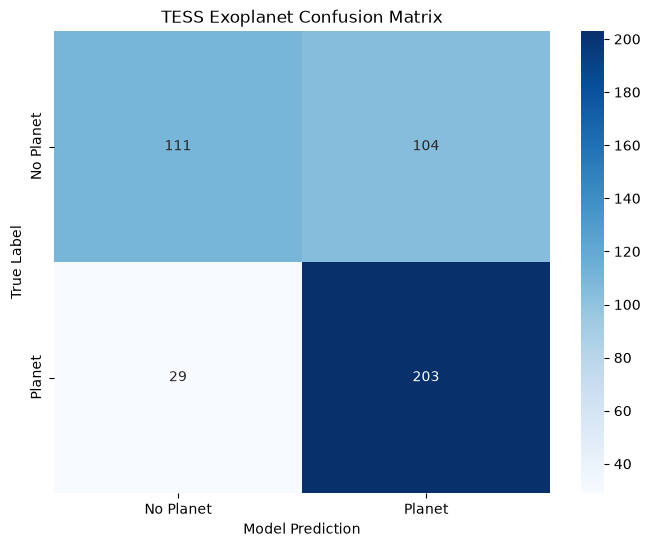

In [9]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

model_5aux.eval() ##

all_preds = []
all_true = []
all_probs = []
all_raw_flux = []

with torch.inference_mode():
    for X_test, y_test, aux_test in test_dataloader:
        X_test, aux_test = X_test.to(device), aux_test.to(device)

        all_raw_flux.append(X_test.cpu())

        mean = X_test.mean(dim = 2, keepdim = True)
        std = X_test.std(dim = 2, keepdim = True)
        X_test = (X_test - mean) / (std + 1e-8)
        
        test_logits = model_5aux(X_test, aux_test) ##
        test_probs = torch.sigmoid(test_logits).squeeze().cpu().numpy() 

        if test_probs.ndim == 0:
            all_probs.append(test_probs)
        else:
            all_probs.extend(test_probs)
        
        all_true.extend(y_test.squeeze().cpu().numpy())

all_true = np.array(all_true)
all_preds = np.array(all_preds)
X_test_raw = torch.cat(all_raw_flux)


fpr, tpr, thresholds = roc_curve(all_true, all_probs)
youden_j = tpr - fpr
best_idx = np.argmax(youden_j)
opt_threshold = thresholds[best_idx]
print(f"Optimal threshold: {opt_threshold:.3f}")

all_preds = (all_probs >= opt_threshold).astype(int)

print(classification_report(all_true, all_preds, target_names = ['No Planet (0)', 'Planet (1)']))

cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize = (8, 6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels = ['No Planet', 'Planet'],
            yticklabels = ['No Planet', 'Planet'])

plt.title("TESS Exoplanet Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Model Prediction")
plt.show()

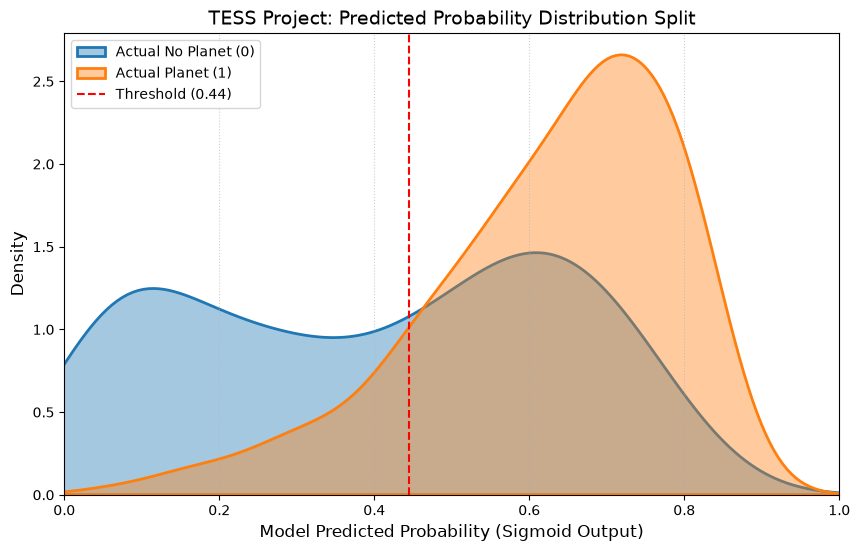

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

probs_arr = np.array(all_probs)
true_arr = np.array(all_true)

plt.figure(figsize=(10, 6))

sns.kdeplot(
    probs_arr[true_arr == 0], 
    label = 'Actual No Planet (0)', 
    fill = True, 
    alpha = 0.4,
    linewidth = 2
)

sns.kdeplot(
    probs_arr[true_arr == 1], 
    label = 'Actual Planet (1)', 
    fill = True, 
    alpha = 0.4,
    linewidth = 2
)

plt.axvline(x = opt_threshold, color = 'red', linestyle = '--', label = f'Threshold ({opt_threshold:.2f})')

plt.title('TESS Project: Predicted Probability Distribution Split', fontsize = 14)
plt.xlabel('Model Predicted Probability (Sigmoid Output)', fontsize = 12)
plt.ylabel('Density', fontsize = 12)
plt.xlim(0, 1)
plt.legend(loc = 'upper left')
plt.grid(axis = 'x', linestyle = ':', alpha = 0.6)
plt.show()

In [11]:
# compute depth from raw (untransformed) flux for each test sample, then bucket
depths = 1.0 - X_test_raw.amin(dim=2).squeeze().cpu().numpy()  # before the -1/clamp/*10 transform
shallow_mask = (true_arr == 1) & (depths < 0.01)
deep_mask    = (true_arr == 1) & (depths >= 0.03)

print("Shallow planets — mean predicted prob:", probs_arr[shallow_mask].mean())
print("Deep planets — mean predicted prob:", probs_arr[deep_mask].mean())

Shallow planets — mean predicted prob: 0.5610006
Deep planets — mean predicted prob: 0.6969179


In [12]:
shallow_np_mask = (true_arr == 0) & (depths < 0.01)
deep_np_mask    = (true_arr == 0) & (depths >= 0.03)

print("Shallow No-Planet — mean predicted prob:", probs_arr[shallow_np_mask].mean())
print("Deep No-Planet — mean predicted prob:", probs_arr[deep_np_mask].mean())

Shallow No-Planet — mean predicted prob: 0.34212938
Deep No-Planet — mean predicted prob: 0.46149293


In [20]:
df["log_duration_fraction"] = np.log(df["Duration_hrs"] / (df["Period (days)"] * 24.0))
df = df[np.isfinite(df["log_period"]) & np.isfinite(df["log_depth"]) & np.isfinite(df["log_duration_fraction"])].reset_index(drop=True)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['final_label'])

scaler3 = StandardScaler()
train_X3 = scaler3.fit_transform(train_df[["log_period", "log_depth", "log_duration_fraction"]])
test_X3 = scaler3.transform(test_df[["log_period", "log_depth", "log_duration_fraction"]])

clf3 = LogisticRegression(max_iter=1000)
clf3.fit(train_X3, train_df["final_label"])
preds3 = clf3.predict(test_X3)
print(classification_report(test_df["final_label"], preds3, target_names=["No Planet (0)", "Planet (1)"]))

               precision    recall  f1-score   support

No Planet (0)       0.66      0.53      0.59       215
   Planet (1)       0.63      0.75      0.69       232

     accuracy                           0.64       447
    macro avg       0.65      0.64      0.64       447
 weighted avg       0.65      0.64      0.64       447



In [ ]:
print(train_df["Depth_ppm"].describe())

In [23]:
diag_dataset = TESSDataset(
    labels_df = test_dataloader.dataset.labels_df,
    lightcurves_dir = data_dir,
    transform = None,
    aux_cols = ["log_period", "log_depth", "log_duration_fraction"],
    aux_stats = test_dataloader.dataset.aux_stats,
    return_id = True
)
diag_loader = DataLoader(diag_dataset, batch_size = 32, shuffle = False)

model_5aux.eval()
records = []
with torch.inference_mode():
    for X, y, aux, tic_id in diag_loader:
        X, aux = X.to(device), aux.to(device)
        mean = X.mean(dim=2, keepdim=True); std = X.std(dim=2, keepdim=True)
        X = (X - mean) / (std + 1e-8)
        probs = torch.sigmoid(model_5aux(X, aux)).squeeze().cpu().numpy()
        probs = np.atleast_1d(probs)
        for i in range(len(tic_id)):
            records.append({
                "tic_id": int(tic_id[i]),
                "true_label": int(y[i].item()),
                "pred_prob": float(probs[i]),
            })

diag_df = pd.DataFrame(records)
no_planet = diag_df[diag_df["true_label"] == 0].copy()
no_planet["dist_from_threshold"] = (no_planet["pred_prob"] - 0.5).abs()
no_planet = no_planet.sort_values("dist_from_threshold")

print(no_planet.head(30)[["tic_id", "pred_prob"]])

Dataset initialized with 447 strictly synced samples.
        tic_id  pred_prob
331   75208638   0.504723
375  243153196   0.494724
115  345333936   0.505410
343  101395259   0.507144
249  199162630   0.508691
195  375199523   0.489110
227   37084932   0.488633
108  237101326   0.488048
271  293567206   0.486019
63   344085117   0.514331
263    7904580   0.480607
374   47617038   0.519597
341   30329585   0.521475
197  418959198   0.522989
300  462715015   0.476747
178  186000935   0.525273
418  438295981   0.529381
64    15827263   0.466541
49     9032368   0.534295
84   165551882   0.535863
308  140830390   0.457159
142   92013169   0.545033
129  389525208   0.454611
370  319068154   0.453786
332  350743714   0.451582
282  398733009   0.553023
419  146244533   0.446216
365  154927364   0.444039
87   113295476   0.556702
242  278866211   0.557835


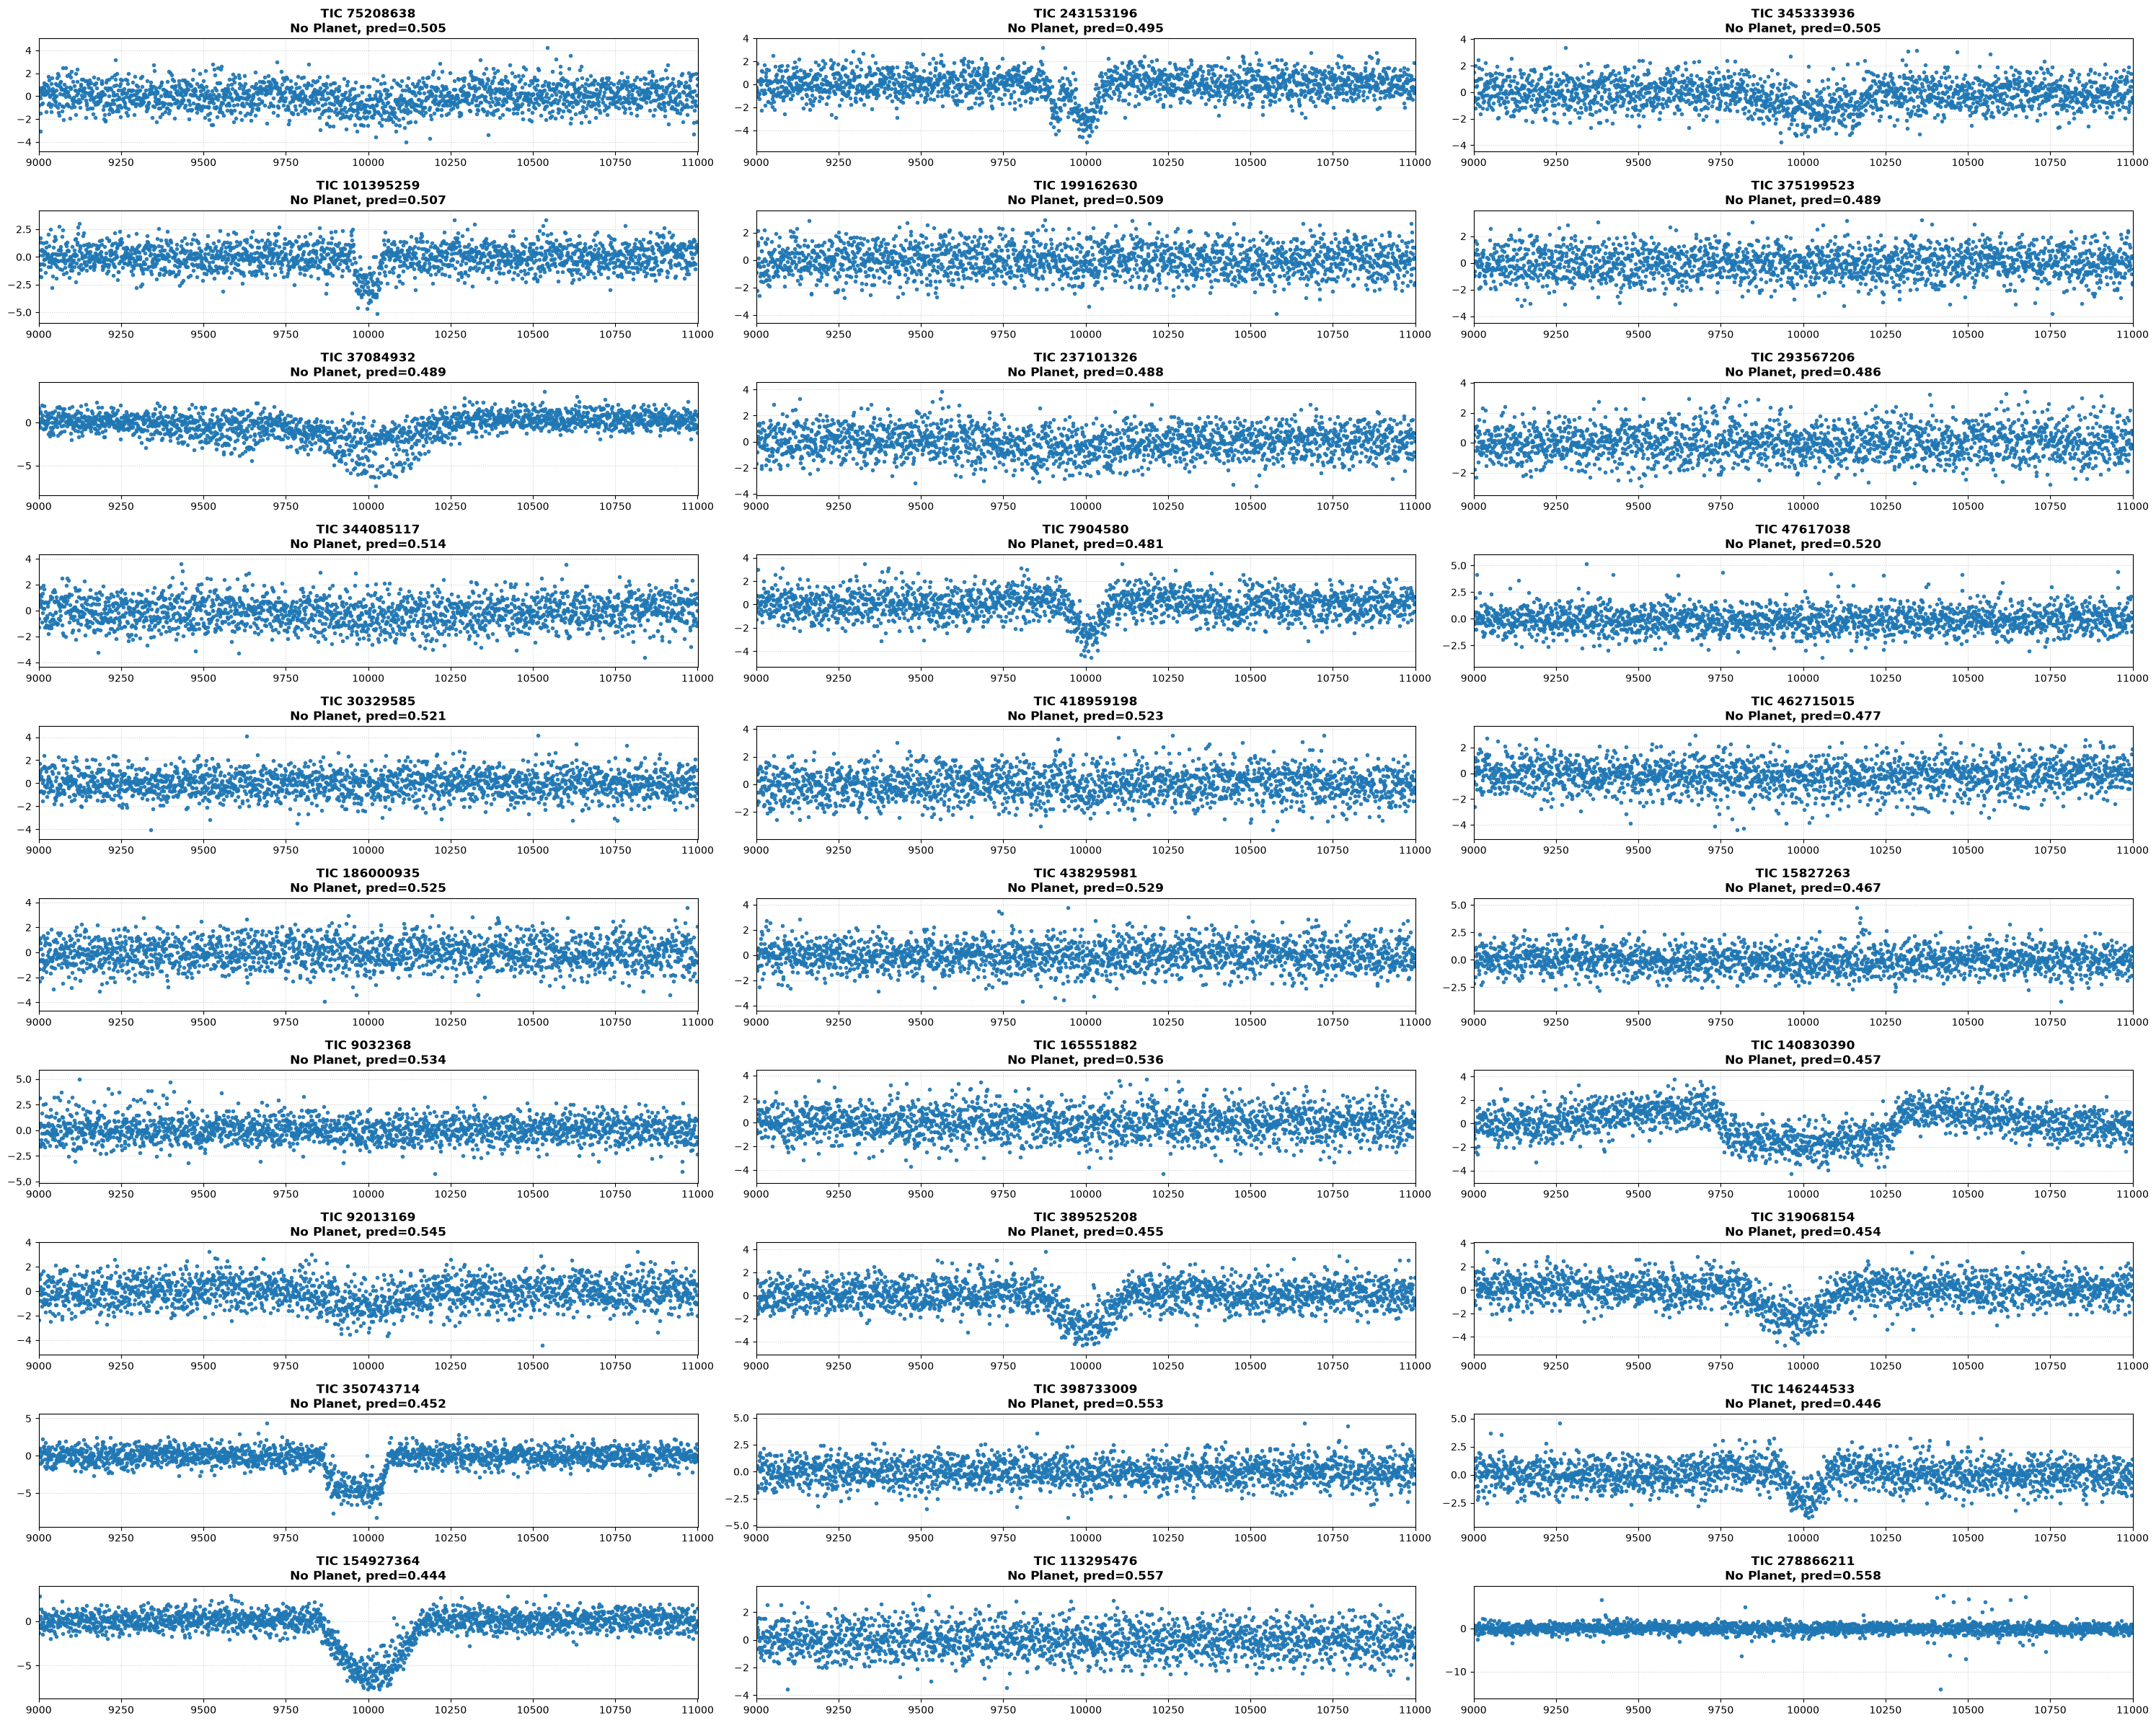

In [24]:
ambiguous_tics = no_planet.head(30)["tic_id"].tolist()

fig, axes = plt.subplots(10, 3, figsize=(30, 24))
axes = axes.flatten()

for i, tic_id in enumerate(ambiguous_tics):
    flux = np.load(Path(data_dir) / f"TIC_{tic_id}.npy").astype(np.float64)
    mean, std = flux.mean(), flux.std()
    focused = ((flux - mean) / (std + 1e-8))[9000:11000]
    x_axis = np.arange(9000, 11000)

    axes[i].plot(x_axis, focused, color='#1f77b4', alpha=0.9, linewidth=0, marker='.')
    axes[i].set_title(f"TIC {tic_id}\nNo Planet, pred={no_planet.iloc[i]['pred_prob']:.3f}", fontweight='bold')
    y_min, y_max = focused.min(), focused.max()
    pad = (y_max - y_min) * 0.1 or 0.5
    axes[i].set_ylim(y_min - pad, y_max + pad)
    axes[i].set_xlim(9000, 11000)
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [27]:
watch_tics = [382188882, 160268701, 243153196]
print(diag_df[diag_df["tic_id"].isin(watch_tics)])

print(diag_df[diag_df["tic_id"].isin([160268701, 382188882])])

        tic_id  true_label  pred_prob
375  243153196           0   0.494724
Empty DataFrame
Columns: [tic_id, true_label, pred_prob]
Index: []


In [21]:
df["duration_fraction"] = df["Duration_hrs"] / (df["Period (days)"] * 24.0)
print(df["duration_fraction"].describe())

count    2231.000000
mean        0.036144
std         0.028129
min         0.000085
25%         0.015858
50%         0.029645
75%         0.049035
max         0.302891
Name: duration_fraction, dtype: float64
